# Figure 1 -- micro-TDE debris from a simulated event

Follows the stellar debris after a **micro-TDE** (`TDE:star2_by_bh1`): the star tidally disrupted by its
$10\,M_\odot$ companion **BH1** while the BH1-star binary encounters the central massive BH **BH2**.
The disruption-time phase space is read **straight from the scattering bundle**, debris are seeded as an
$n=3$ polytrope with the penetration-dependent spin, advanced ballistically in the BH1+BH2 field, and
classified into *bound to BH1* (mini-disk), *bound to BH2* (returns to the central BH), or *unbound*
(ejected).

The figure: a **snapshot** of the debris (points, coloured by specific energy about BH2), with four
insets -- the full ejecta extent, the BH1 mini-disk, the **total** energy distribution
$dM/d\ln|\varepsilon|$, and the **total** fallback rate
$dM/dt = dM/dt_{\rm BH1}+dM/dt_{\rm BH2}$ (the combined "lightcurve" across both accretors).

Requires `debris_tracer.py` on the path.

## 1. Setup & style

Matches the paper figures: Computer-Modern (mathtext `cm`) fonts, ticks pointing **in** on all four
sides with **minor ticks** everywhere (including the colour bar), larger tick/label fonts.

In [1]:
import sys, os
for _p in ('../pkg', 'pkg', '.'):
    if os.path.isdir(_p) and _p not in sys.path: sys.path.insert(0, _p)
import numpy as np, matplotlib as mpl, matplotlib.pyplot as plt
from matplotlib.ticker import AutoMinorLocator, LogLocator, NullFormatter
import debris_tracer as dt

plt.rcParams.update({
    "figure.dpi":120, "savefig.dpi":200,
    "font.family":"serif", "font.serif":["cmr10","DejaVu Serif"],
    "mathtext.fontset":"cm", "axes.formatter.use_mathtext":True, "axes.unicode_minus":False,
    "font.size":15, "axes.labelsize":18, "xtick.labelsize":14, "ytick.labelsize":14,
    "legend.fontsize":12.5, "axes.linewidth":1.0,
    "xtick.direction":"in", "ytick.direction":"in", "xtick.top":True, "ytick.right":True,
    "xtick.minor.visible":True, "ytick.minor.visible":True,
    "xtick.major.size":7, "ytick.major.size":7, "xtick.minor.size":4, "ytick.minor.size":4,
    "xtick.major.width":1.0, "ytick.major.width":1.0, "xtick.minor.width":0.8, "ytick.minor.width":0.8,
})

def ticks_all(ax, log=False, labels=True, lblsize=None):
    """ticks in on all 4 sides, with minor ticks (log-aware)."""
    ax.tick_params(which="both", direction="in", top=True, right=True,
                   labelbottom=labels, labelleft=labels,
                   labelsize=(lblsize if lblsize else mpl.rcParams["xtick.labelsize"]))
    if log:
        for a in (ax.xaxis, ax.yaxis):
            a.set_minor_locator(LogLocator(base=10, subs=np.arange(2,10), numticks=100))
            a.set_minor_formatter(NullFormatter())
    else:
        ax.xaxis.set_minor_locator(AutoMinorLocator()); ax.yaxis.set_minor_locator(AutoMinorLocator())

def inside_title(ax, text, fs=11):
    """panel designation placed INSIDE the axes (upper-left)."""
    ax.text(0.035, 0.965, text, transform=ax.transAxes, ha="left", va="top", fontsize=fs,
            bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="0.6", lw=0.6, alpha=0.85))
print("style ready")

style ready


## 2. Read a micro-TDE event from your bundle

Point `BUNDLE` at your file and pick the event -- either by `ROW` (index into the $\mu$-TDE subset) or by
nearest $(M_\bullet, a_{\rm bin}, e_{\rm bin})$ cell via `MATCH`.  `read_bundle_row` returns the
disruption-time phase space (central BH, BH1, star) in code units ($G=1$, $M_\odot$, AU, $V_1$).

In [3]:
BUNDLE = os.environ.get("SMBH_BUNDLE", "../../../data/bhstar/campaign2_rp10/smbh_bhstar_bundle.h5")   # <-- your bundle
ROW    = 0                            # index into the mu-TDE subset; or set MATCH and ROW=None
MATCH  = None                         # e.g. dict(M_smbh=1e6, a_bin=0.1, e_bin=0.3)
N      = int(os.environ.get("DEBRIS_N", 10000))   # debris particles (env override for quick previews)
POLY_N = 3.0                          # polytropic index (3 = Sun-like)

mu = dt.mutde_indices(BUNDLE)
print(f"{len(mu)} micro-TDE rows in {BUNDLE}")
st = dt.read_bundle_row(BUNDLE, row_index=ROW, match=MATCH)
M2, M1, m_star = st["M2"], st["m_BH1"], st["m_star"]
print(f"event: {st['note']}")
print(f"  M_bullet={M2:.3e} Msun,  m_BH1={M1:.0f},  m_star={m_star:.2f},  R_star={st['R_star']:.4f} AU")
print(f"  disruption separation |r_star - r_BH1| = {np.linalg.norm(st['r_star']-st['r_BH1']):.4f} AU")

788113 micro-TDE rows in ../smbh_bhstar_bundle.h5
event: bundle row 78 (TDE:star2_by_bh1)
  M_bullet=3.162e+01 Msun,  m_BH1=10,  m_star=1.00,  R_star=0.0047 AU
  disruption separation |r_star - r_BH1| = 0.0100 AU


## 3. Seed debris and integrate

Two integrations from the same seed: a short, fine-softening one that resolves the **BH1 mini-disk**, and
a longer one (larger softening) that follows the **return to BH2**.

In [4]:
r, v, om, info = dt.make_debris_ic(st, N, n=POLY_N, spin=True, seed=1)
print(f"penetration beta = r_t,*/r_peri = {info['beta_pen']:.2f},  spin/breakup = {info['spin_over_breakup']:.2f}")

r_in = info["r_peri"]
t1   = 8*2*np.pi*np.sqrt(r_in**3/M1)                      # ~8 inner orbits about BH1
eps2_0 = 0.5*np.einsum("ij,ij->i", v, v) - M2/np.linalg.norm(r, axis=1)   # debris energy wrt BH2 at seed
bnd2   = eps2_0 < 0
Tb   = 2*np.pi*np.sqrt((M2/(2*np.abs(eps2_0[bnd2])))**3/M2)
t_end= 3*float(np.percentile(Tb, 25))
a_bound = M2/(2*np.abs(eps2_0[bnd2]))
span_main = 2.0*float(np.median(a_bound)); span_in = 12.0*r_in

res1 = dt.integrate_debris(st, r, v, t1,    n_frames=90,  soft=r_in)        # mini-disk
res2 = dt.integrate_debris(st, r, v, t_end, n_frames=160, soft=3.0*r_in)    # return to BH2
print("integrations done")

penetration beta = r_t,*/r_peri = 2.27,  spin/breakup = 5.02
integrations done


## 4. Snapshot, energies, hierarchical fate, and the TOTAL fallback

Fate (no double counting): **bound to BH1** from the frozen-in $\varepsilon_{\rm BH1}<0$ at disruption;
the remainder **bound to BH2** from the final $\varepsilon_{\rm BH2}<0$; else **unbound**.  Each bound
particle's return time is Kepler, $t_{\rm fb}=2\pi M_c(2|\varepsilon|)^{-3/2}$ (years), and the total
fallback is the sum over both accretors.

In [5]:
cl2 = dt.classify(res2, frame=-1); cl0 = dt.classify(res2, frame=0)
eps2 = cl2["eps_BH2"]; eps1f = cl0["eps_BH1"]
rb2_f = res2["traj_bh"][1,-1,:2]
xy2 = res2["traj_deb"][:,-1,:2] - rb2_f                    # debris wrt BH2 (snapshot)
bh1_orbit = res2["traj_bh"][0,:,:2] - res2["traj_bh"][1,:,:2]
rb1_s = res1["traj_bh"][0,-1,:2]
xy1 = res1["traj_deb"][:,-1,:2] - rb1_s                    # mini-disk snapshot (wrt BH1)
eps1_s = dt.classify(res1, frame=-1)["eps_BH1"]

YR = dt.YR_PER_T; dm = m_star/N
bh1b = eps1f < 0
bh2b = (~bh1b) & (eps2 < 0)
eB1 = np.abs(eps1f[bh1b]); eB2 = np.abs(eps2[bh2b])
tB1 = (2*np.pi*M1*(2*eB1)**-1.5)*YR                        # fallback times [yr]
tB2 = (2*np.pi*M2*(2*eB2)**-1.5)*YR
nej = int(np.sum((~bh1b) & (eps2>=0)))
print(f"bound->BH1 {bh1b.sum()} ({bh1b.mean()*100:.0f}%) | bound->BH2 {bh2b.sum()} "
      f"({bh2b.mean()*100:.0f}%) | unbound {nej} ({nej/N*100:.0f}%)")

bound->BH1 4075 (41%) | bound->BH2 0 (0%) | unbound 5925 (59%)


## 5. The figure

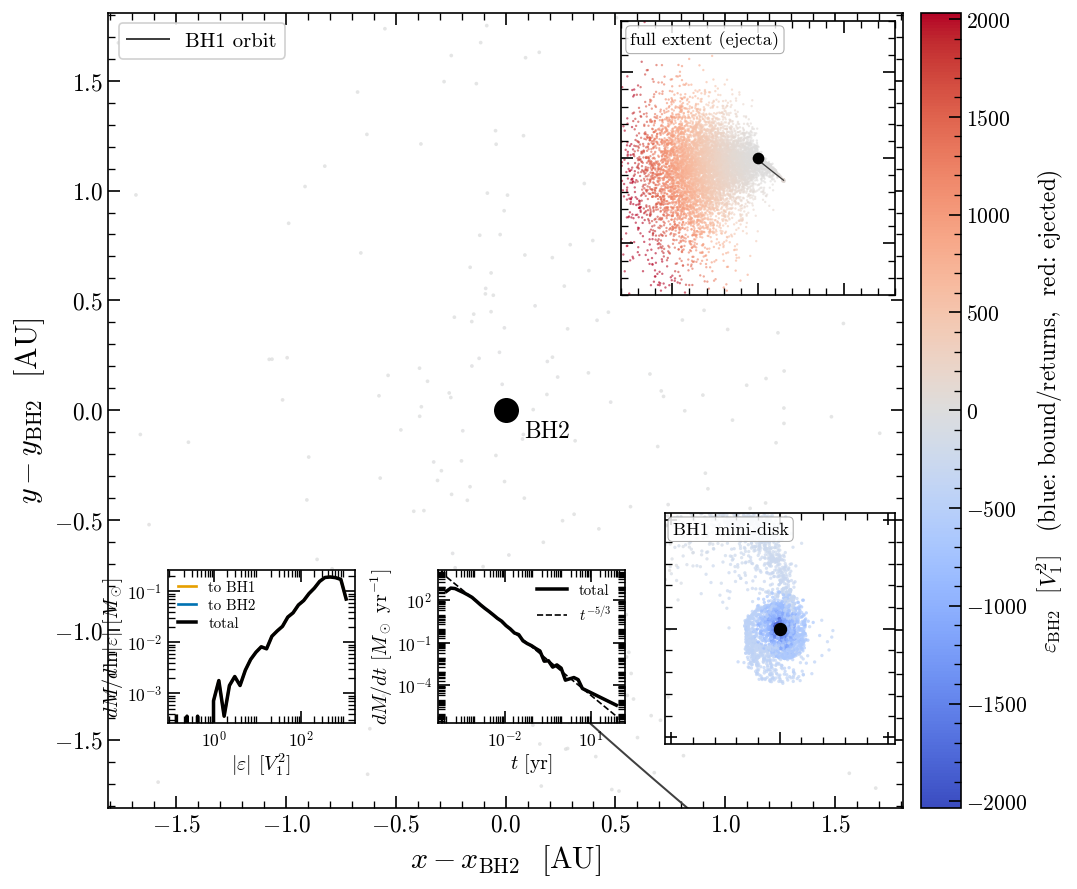

In [6]:
C_B1, C_B2, C_TOT = "#E69F00", "#0072B2", "k"       # BH1=orange, BH2=blue, total=black
clim = float(np.nanpercentile(np.abs(eps2), 98))+1e-30
norm = mpl.colors.Normalize(-clim, clim); CMAP = mpl.cm.coolwarm

fig, ax = plt.subplots(figsize=(9.6, 8.6))

# ---- MAIN: snapshot coloured by energy wrt BH2 ----
inm = (np.abs(xy2[:,0])<span_main) & (np.abs(xy2[:,1])<span_main)
ax.scatter(xy2[inm,0], xy2[inm,1], c=eps2[inm], cmap=CMAP, norm=norm, s=5, alpha=0.75,
           linewidths=0, rasterized=True)
ax.plot(bh1_orbit[:,0], bh1_orbit[:,1], "-", color="0.25", lw=1.2, label="BH1 orbit")
ax.plot(0,0,"o",ms=14,color="k")
ax.annotate("BH2",(0,0),textcoords="offset points",xytext=(11,-16),fontsize=14)
ax.set_xlim(-span_main,span_main); ax.set_ylim(-span_main,span_main); ax.set_aspect("equal")
ax.set_xlabel(r"$x-x_{\rm BH2}$  [AU]"); ax.set_ylabel(r"$y-y_{\rm BH2}$  [AU]")
ticks_all(ax); ax.legend(loc="upper left", framealpha=0.9)
sm = mpl.cm.ScalarMappable(norm=norm, cmap=CMAP); sm.set_array([])
cb = fig.colorbar(sm, ax=ax, fraction=0.046, pad=0.02)
cb.set_label(r"$\varepsilon_{\rm BH2}$  [$V_1^2$]   (blue: bound/returns,  red: ejected)", fontsize=14)
cb.ax.tick_params(which="both", direction="in", labelsize=13)
cb.ax.yaxis.set_minor_locator(AutoMinorLocator())        # minor ticks on the colour bar

# ---- INSET A: full extent / ejecta (upper-right) ----
ejec = xy2[(~bh1b)&(eps2>=0)]
R = 1.05*np.nanpercentile(np.abs(ejec),99.0) if ejec.size else span_main*5
axA = ax.inset_axes([0.645, 0.645, 0.345, 0.345])
axA.scatter(xy2[:,0],xy2[:,1],c=eps2,cmap=CMAP,norm=norm,s=2,alpha=0.6,linewidths=0,rasterized=True)
axA.plot(bh1_orbit[:,0],bh1_orbit[:,1],"-",color="0.25",lw=0.8); axA.plot(0,0,"o",ms=6,color="k")
axA.add_patch(mpl.patches.Rectangle((-span_main,-span_main),2*span_main,2*span_main,fill=False,ec="0.35",lw=0.8))
axA.set_xlim(-R,R); axA.set_ylim(-R,R); axA.set_aspect("equal")
ticks_all(axA, labels=False); inside_title(axA, "full extent (ejecta)")

# ---- INSET B: BH1 mini-disk (lower-right) ----
axB = ax.inset_axes([0.70, 0.075, 0.29, 0.30])
nrm1 = mpl.colors.Normalize(-np.nanpercentile(np.abs(eps1_s),95)-1e-30, np.nanpercentile(np.abs(eps1_s),95)+1e-30)
axB.scatter(xy1[:,0],xy1[:,1],c=eps1_s,cmap=CMAP,norm=nrm1,s=4,alpha=0.7,linewidths=0,rasterized=True)
axB.plot(0,0,"o",ms=7,color="k")
axB.set_xlim(-span_in,span_in); axB.set_ylim(-span_in,span_in); axB.set_aspect("equal")
ticks_all(axB, labels=False); inside_title(axB, "BH1 mini-disk")

# ---- INSET C: TOTAL energy distribution dM/dln|eps| ----
axC = ax.inset_axes([0.075, 0.085, 0.235, 0.235])
eall = np.concatenate([eB1,eB2]); eb = np.logspace(np.log10(eall.min()),np.log10(eall.max()),34)
ec = np.sqrt(eb[:-1]*eb[1:]); dln = np.diff(np.log(eb))
for en,col,lab in [(eB1,C_B1,"to BH1"),(eB2,C_B2,"to BH2")]:
    h,_=np.histogram(en,bins=eb); axC.plot(ec,h*dm/dln,color=col,lw=1.6,label=lab)
htot,_=np.histogram(eall,bins=eb); axC.plot(ec,htot*dm/dln,color=C_TOT,lw=2.1,label="total")
axC.set_xscale("log"); axC.set_yscale("log"); axC.set_box_aspect(0.82)
axC.set_xlabel(r"$|\varepsilon|$ [$V_1^2$]", fontsize=12, labelpad=1)
axC.set_ylabel(r"$dM/d\ln|\varepsilon|$ [$M_\odot$]", fontsize=12, labelpad=1)
ticks_all(axC, log=True, lblsize=10.5); axC.legend(fontsize=9, frameon=False, loc="upper left",
                                                   handlelength=1.2, labelspacing=0.3, borderaxespad=0.3)

# ---- INSET D: TOTAL fallback rate dM/dt = dM/dt_BH1 + dM/dt_BH2 ----
axD = ax.inset_axes([0.415, 0.085, 0.235, 0.235])
tall = np.concatenate([tB1,tB2]); tb = np.logspace(np.log10(tall.min()),np.log10(tall.max()),42)
tc = np.sqrt(tb[:-1]*tb[1:]); dtw = np.diff(tb)
for tt,col in [(tB1,C_B1),(tB2,C_B2)]:
    h,_=np.histogram(tt,bins=tb); g=h>0; axD.loglog(tc[g],(h*dm/dtw)[g],color=col,lw=1.4,alpha=0.9)
htot,_=np.histogram(tall,bins=tb); g=htot>0
axD.loglog(tc[g],(htot*dm/dtw)[g],color=C_TOT,lw=2.1,label="total")
iref=np.where(g)[0][len(np.where(g)[0])//4]
axD.loglog(tc[g],(htot*dm/dtw)[g][np.searchsorted(np.where(g)[0],iref)]*(tc[g]/tc[iref])**(-5/3),
           "k--",lw=1.0,label=r"$t^{-5/3}$")
axD.set_box_aspect(0.82)
axD.set_xlabel(r"$t$ [yr]", fontsize=12, labelpad=1)
axD.set_ylabel(r"$dM/dt$ [$M_\odot$ yr$^{-1}$]", fontsize=12, labelpad=1)
ticks_all(axD, log=True, lblsize=10.5); axD.legend(fontsize=9, frameon=False, loc="upper right")

fig.savefig("debris_fig1.png", bbox_inches="tight"); fig.savefig("debris_fig1.pdf", bbox_inches="tight")
plt.show()